# ELA U-Net 기준 실험

- 작성자: kimjihwan
- 상태: **완료 — Colab 저장 출력 확인 (2026-11-24)**
- 작성일: 2026-11-24
- 관련 작업: T10 ELA U-Net 기본 실험
- [보고서](../../docs/ela_unet/EXP_kimjihwan_003_ela_unet_baseline.md) · 비교 기준: [002 RGB U-Net·손실 비교](../../docs/rgb_unet/EXP_kimjihwan_002_rgb_unet_loss_compare.md) · 규약: [전처리 안내](../../docs/preprocessing.md)

## 목적·가설

ELA 3채널 입력 ResNet-50 U-Net을 002의 RGB U-Net과 같은 조건으로 학습해, 입력을 RGB에서 ELA로 바꿨을 때 검출 성능이 어떻게 달라지는지 확인함. 002에서 RGB U-Net은 AutoSplice JPEG100에서 높았지만 JPEG90·75와 CocoGlide에서 크게 떨어져 압축 이력에 의존한 것으로 보였음. ELA는 압축 오차 자체를 입력으로 쓰므로 같은 경향이 더 강하거나 다르게 나타나는지도 함께 봄.

## 002에서 바꾼 점

- 입력: RGB 대신 ELA(quality 90, scale 15, subsampling 2). 팀 확정 규약대로 **원본 전체에서 ELA를 먼저 계산한 뒤** 같은 위치로 256 크롭하고 같은 좌우반전을 적용함. 평가는 원본 전체의 ELA를 `pad_image`로 패딩해 추론함.
- 손실: 002에서 val 조작 평균 F1로 선택된 `bce_dice`(BCE + 이미지별 Dice, 1:1) 한 조건만 학습함.
- 그 밖의 데이터·모델 구조·최적화·학습량·조기 종료·평가·테스트 범위는 002와 같음. JPEG 증강은 비교 조건을 맞추기 위해 넣지 않음.
- 그림 표본을 파일 경로로 구분하고 그래프 제목을 영어로 바꿈(002 그림의 한글 깨짐 방지).

ELA 정규화(0~1 변환 후 ImageNet 평균·표준편차)와 ELA 입력에 RGB 사전학습 conv1을 그대로 쓰는 방식은 001과 같은 임시 선택이며 T06 미확정 항목임. 팀원이 VS Code의 Colab 원격 커널(GPU)에서 위에서부터 실행하고 출력이 포함된 노트북을 저장함.

## 1. Drive·공통 코드·실행 환경 준비

공유 Drive의 `AI_Forensics/datasets/`와 `AI_Forensics/project/scripts/`를 읽음. 체크포인트와 epoch별 기록은 공유 폴더 밖의 개인 폴더 `MyDrive/AI_Forensics_runs/kimjihwan/`에 저장함(T16 저장 구조 미정). 데이터·가중치는 Git에 올리지 않음.

In [1]:
from pathlib import Path
from google.colab import drive
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import random
import sys
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, features
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet50, ResNet50_Weights

drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")
data_root = work_root / "datasets"
experiment_name = "EXP_kimjihwan_003_ela_unet_baseline"
run_root = Path("/content/drive/MyDrive/AI_Forensics_runs/kimjihwan") / experiment_name
split_path = project_root / "scripts/splits/autosplice_seed42.csv"
archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}
extract_paths = {"AutoSplice": data_root, "CocoGlide": data_root / "CocoGlide"}
required = ["scripts/__init__.py", "scripts/datasets.py", "scripts/preprocessing.py", "scripts/evaluation.py",
            "scripts/splits/autosplice_seed42.csv"]
for relative in required:
    if not (project_root / relative).is_file():
        raise FileNotFoundError(f"Drive에 공통 파일을 업로드해야 함: {relative}")

sys.path.insert(0, str(project_root))
importlib.invalidate_caches()
import scripts
import scripts.datasets as dataset_module
import scripts.preprocessing as preprocessing_module
import scripts.evaluation as evaluation_module

for module, relative in [(scripts, "scripts/__init__.py"), (dataset_module, "scripts/datasets.py"),
                         (preprocessing_module, "scripts/preprocessing.py"), (evaluation_module, "scripts/evaluation.py")]:
    if Path(module.__file__).resolve() != (project_root / relative).resolve():
        raise ImportError(f"프로젝트의 모듈을 불러오도록 커널을 재시작해야 함: {relative}")
    print("불러온 코드:", module.__file__)

from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records, cocoglide_records
from scripts.preprocessing import load_rgb, load_binary_mask, crop_pair, make_ela, pad_image, unpad_image
from scripts.evaluation import confusion_counts, pixel_f1, iou, false_positive_rate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("실행 시각 UTC:", datetime.now(timezone.utc).isoformat())
print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "Pillow", "pandas", "matplotlib", "torch", "torchvision"):
    print(package, importlib.metadata.version(package))
print("JPEG library:", features.version("jpg"))
print("CUDA:", torch.version.cuda, "/ cuDNN:", torch.backends.cudnn.version())
print("TF32 matmul / cuDNN:", torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32)
print("CPU 코어:", os.cpu_count())
print("장치:", device)
if device.type != "cuda":
    raise RuntimeError("GPU 런타임에서 실행해야 함.")
properties = torch.cuda.get_device_properties(0)
print("GPU:", properties.name, f"{properties.total_memory / 1024**3:.1f} GiB")
print("실행 기록 폴더:", run_root)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/__init__.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/datasets.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/preprocessing.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/evaluation.py
실행 시각 UTC: 2026-11-23T19:10:51.227169+00:00
Python: 3.13.16
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
torch 2.14.1+cu130
torchvision 0.29.1+cu130
JPEG library: 6.2
CUDA: 13.0 / cuDNN: 92800
TF32 matmul / cuDNN: False True
CPU 코어: 12
장치: cuda
GPU: NVIDIA L4 22.0 GiB
실행 기록 폴더: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_003_ela_unet_baseline


In [2]:
# Git 저장소의 LF 줄바꿈 기준 해시임. Windows에서 CRLF로 바뀐 파일을 올리면 일치하지 않음.
expected_files = {
    "scripts/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "scripts/datasets.py": "435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88",
    "scripts/preprocessing.py": "73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f",
    "scripts/evaluation.py": "ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52",
    "scripts/splits/autosplice_seed42.csv": "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e",
}
for relative, expected_hash in expected_files.items():
    actual_hash = sha256(project_root / relative)
    print(relative, actual_hash)
    if actual_hash != expected_hash:
        raise ValueError(f"검토한 코드·분할 버전과 일치해야 함: {relative}")

seed = 42
config = dict(
    input_mode="ela", ela_quality=90, ela_scale=15, ela_subsampling=2, ela_order="full-image ELA -> crop -> flip",
    mask_foreground=255, train_quality=100, train_kinds=["manipulated"],
    crop_size=256, crop_stride=16, flip_probability=0.5,
    encoder="torchvision resnet50", encoder_weights="IMAGENET1K_V2", normalization="ELA/255 then ImageNet mean/std", conv1="RGB pretrained weights as-is",
    optimizer="Adam", learning_rate=1e-4, batch_size=16, num_workers=2,
    max_epochs=30, patience=5, selection="val manipulated mean F1",
    dice_eps=1.0, threshold=0.5, pad_multiple=32, pad_mode="pad_image/unpad_image (bottom-right zero, pixel 0)",
    cocoglide_jpeg_quality=100, cocoglide_jpeg_subsampling=0, seed=seed,
)
conditions = ["bce_dice"]
config_hash = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
for key, value in config.items():
    print(f"{key}: {value}")
print("손실 조건:", conditions)
print("설정 해시:", config_hash)


def set_seed(value):
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)
    torch.cuda.manual_seed_all(value)


set_seed(seed)
torch.backends.cudnn.benchmark = False

scripts/__init__.py e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/preprocessing.py 73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f
scripts/evaluation.py ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
input_mode: ela
ela_quality: 90
ela_scale: 15
ela_subsampling: 2
ela_order: full-image ELA -> crop -> flip
mask_foreground: 255
train_quality: 100
train_kinds: ['manipulated']
crop_size: 256
crop_stride: 16
flip_probability: 0.5
encoder: torchvision resnet50
encoder_weights: IMAGENET1K_V2
normalization: ELA/255 then ImageNet mean/std
conv1: RGB pretrained weights as-is
optimizer: Adam
learning_rate: 0.0001
batch_size: 16
num_workers: 2
max_epochs: 30
patience: 5
selection: val manipulated mean F1
dice_eps: 1.0
threshold: 0.5
pad_multiple: 32
pad

## 2. 데이터 준비

두 ZIP을 해시 확인 후 해제함. 학습은 train 조작 이미지(JPEG 100), 검증은 val 조작 361장(F1·IoU)과 val 정상 227장(오탐률 기록)을 사용함.

테스트 목록은 004와 같게 구성함. AutoSplice test는 JPEG 100·90·75 조작본을 각각 평가하고 정상 원본은 한 번만 포함함. CocoGlide는 PNG를 RGB로 변환해 JPEG quality 100, subsampling 0으로 저장한 파일을 입력으로 사용하고, 정답 비교는 원본 크기의 마스크로 함.

In [3]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}
for name, source in archive_paths.items():
    prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])

records_by_quality = {q: autosplice_records(data_root / "AutoSplice", split_path, quality=q) for q in (100, 90, 75)}
base = records_by_quality[100]
train_records = [r for r in base if r["split"] == "train" and r["kind"] == "manipulated"]
val_records = [r for r in base if r["split"] == "val"]
for record in train_records + val_records:
    record["input_path"] = record["image_path"]

test_records = []
for quality, records in records_by_quality.items():
    for record in records:
        if record["split"] != "test" or (record["kind"] == "normal" and quality != 100):
            continue
        variant = "original" if record["kind"] == "normal" else f"JPEG{quality}"
        test_records.append(dict(record, variant=variant, input_path=record["image_path"], input_conversion="none"))

cocoglide_root = data_root / "CocoGlide"
jpeg_root = work_root / "unet_inputs" / "CocoGlide_JPEG100_444"
converted = 0
for record in cocoglide_records(cocoglide_root):
    source = record["image_path"]
    target = (jpeg_root / source.relative_to(cocoglide_root)).with_suffix(".jpg")
    target.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(source) as image:
        if image.format != "PNG":
            raise ValueError(f"CocoGlide 원본은 PNG여야 함: {source}")
        size = image.size
        image.convert("RGB").save(target, format="JPEG", quality=config["cocoglide_jpeg_quality"],
                                  subsampling=config["cocoglide_jpeg_subsampling"])
    with Image.open(target) as image:
        if image.format != "JPEG" or image.size != size:
            raise ValueError(f"변환 형식과 원본 크기가 일치해야 함: {target}")
    converted += 1
    test_records.append(dict(record, variant="PNG", input_path=target, input_conversion="PNG_to_JPEG100_444"))

if converted != 1024:
    raise ValueError("CocoGlide 변환 수는 1,024장이어야 함.")
if pd.Series([str(r["image_path"]) for r in test_records]).duplicated().any():
    raise ValueError("테스트 목록에 같은 이미지가 중복되지 않아야 함.")
assert {r["split"] for r in train_records} == {"train"} and {r["split"] for r in val_records} == {"val"}

print("학습 조작 이미지:", len(train_records))
display(pd.DataFrame(val_records).groupby("kind").size().rename("val images").to_frame())
test_table = pd.DataFrame(test_records)
display(test_table.groupby(["dataset", "split", "variant", "input_conversion", "kind"]).size().rename("images").reset_index())
print("테스트 이미지 합계:", len(test_records))

AutoSplice 기존 해제 파일 사용
CocoGlide 기존 해제 파일 사용
학습 조작 이미지: 2925


,val images
kind,
manipulated,361
normal,227


,dataset,split,variant,input_conversion,kind,images
0,AutoSplice,test,JPEG100,none,manipulated,335
1,AutoSplice,test,JPEG75,none,manipulated,335
2,AutoSplice,test,JPEG90,none,manipulated,335
3,AutoSplice,test,original,none,normal,228
4,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,manipulated,512
5,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,normal,512


테스트 이미지 합계: 2257


## 3. 학습 입력 구성

이미지마다 원본 전체에서 ELA를 먼저 계산한 뒤, 무작위 위치(16의 배수 좌표)에서 ELA와 마스크를 같은 256×256으로 자르고 확률 0.5로 둘을 같이 좌우반전함(팀 확정 순서). 모델 입력은 ELA 3채널뿐임. 무작위 값은 DataLoader 작업자마다 고정 시드에서 나오는 torch 난수를 사용함.

배치 입력 (16, 3, 256, 256) torch.float32 / 마스크 (16, 1, 256, 256) torch.float32 [0.0, 1.0]
epoch당 step: 182
배치 마스크 비율: [0.248, 0.566, 0.757, 0.827, 0.668, 0.555, 0.5, 0.815, 0.068, 0.786, 0.543, 0.773, 0.673, 0.283, 0.666, 0.071]


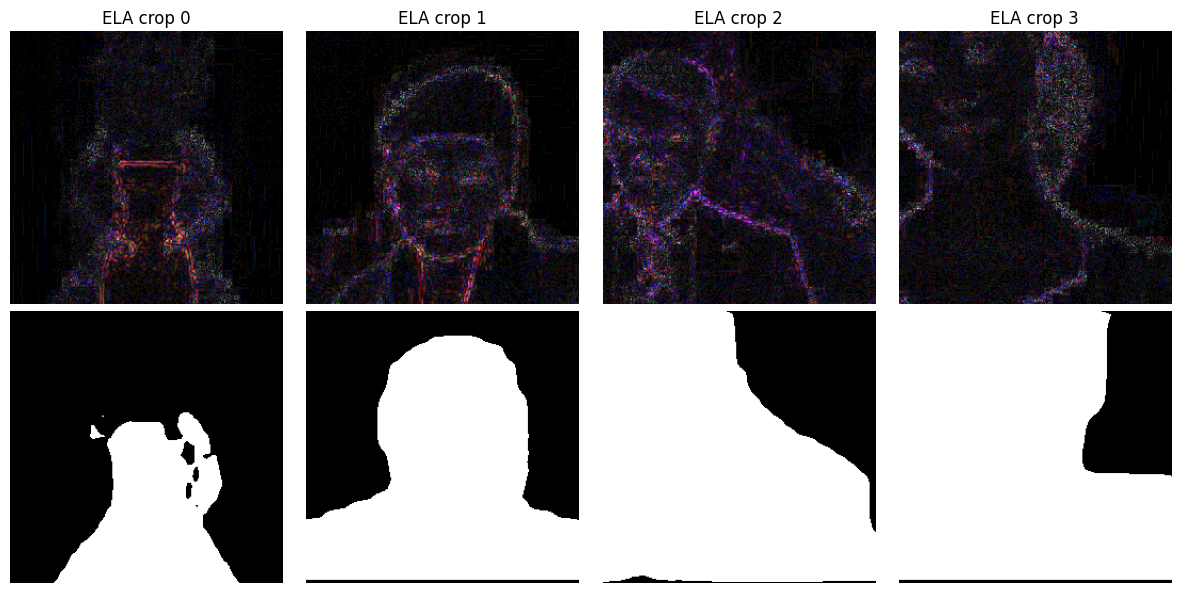

In [4]:
imagenet_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
imagenet_std = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def load_pair(record):
    rgb = load_rgb(record["input_path"])
    if record["kind"] == "normal":
        mask = np.zeros(rgb.shape[:2], dtype=np.uint8)
    else:
        mask = load_binary_mask(record["mask_path"], foreground_value=config["mask_foreground"])
    if rgb.shape[:2] != mask.shape:
        raise ValueError(f"이미지와 마스크 크기가 같아야 함: {record['input_path']}")
    return rgb, mask


def ela_of(rgb):
    return make_ela(rgb, quality=config["ela_quality"], scale=config["ela_scale"], subsampling=config["ela_subsampling"])


def to_input(array):
    normalized = (array.astype(np.float32) / 255.0 - imagenet_mean) / imagenet_std
    return torch.from_numpy(normalized.transpose(2, 0, 1).copy())


class TrainCrops(torch.utils.data.Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        rgb, mask = load_pair(self.records[index])
        ela = ela_of(rgb)
        size, stride = config["crop_size"], config["crop_stride"]
        top = int(torch.randint(0, (rgb.shape[0] - size) // stride + 1, ())) * stride
        left = int(torch.randint(0, (rgb.shape[1] - size) // stride + 1, ())) * stride
        ela, mask = crop_pair(ela, mask, top=top, left=left, height=size, width=size)
        if torch.rand(()) < config["flip_probability"]:
            ela, mask = ela[:, ::-1].copy(), mask[:, ::-1].copy()
        return to_input(ela), torch.from_numpy(mask[None].astype(np.float32))


def make_train_loader(condition_seed):
    generator = torch.Generator().manual_seed(condition_seed)
    return torch.utils.data.DataLoader(TrainCrops(train_records), batch_size=config["batch_size"], shuffle=True,
                                       drop_last=True, num_workers=config["num_workers"], generator=generator,
                                       pin_memory=True, persistent_workers=config["num_workers"] > 0)


x, y = next(iter(make_train_loader(seed)))
print("배치 입력", tuple(x.shape), x.dtype, "/ 마스크", tuple(y.shape), y.dtype, torch.unique(y).tolist())
print("epoch당 step:", len(train_records) // config["batch_size"])
print("배치 마스크 비율:", [round(v, 3) for v in y.mean(dim=(1, 2, 3)).tolist()])

figure, axes = plt.subplots(2, 4, figsize=(12, 6))
for column in range(4):
    axes[0, column].imshow((x[column].numpy().transpose(1, 2, 0) * imagenet_std + imagenet_mean).clip(0, 1))
    axes[1, column].imshow(y[column, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, column].set_title(f"ELA crop {column}")
    for row in range(2):
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()

## 4. 모델·손실·평가 함수

모델은 001과 같은 ResNet-50 U-Net임. 이후 ELA·RGB+ELA 실험에서도 같은 클래스를 쓰도록 입력 채널 인자를 유지함.

이미지별 Dice는 이미지마다 `1 − (2·Σpy + ε) / (Σp + Σy + ε)`를 구해 배치 평균함(ε=1). 크롭에 조작 영역이 없으면 예측이 0에 가까울수록 손실이 0에 가까워짐.

평가는 원본 크기 이미지 전체에서 ELA를 계산한 뒤 `pad_image`로 우하단 제로 패딩해 추론하고 `unpad_image`로 원래 크기로 되돌린 뒤 임계값 0.5를 적용함. 정답 마스크는 패딩하지 않음. 조작 이미지는 F1·IoU, 정상 이미지는 픽셀 오탐률을 계산해 이미지별로 평균함(004와 같은 집계).

In [5]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels + skip_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.block(x)


class ResNet50UNet(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        encoder = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        if in_channels == 6:
            rgb_weight = encoder.conv1.weight.detach().clone()
            encoder.conv1 = nn.Conv2d(6, 64, 7, stride=2, padding=3, bias=False)
            with torch.no_grad():
                encoder.conv1.weight.copy_(torch.cat([rgb_weight, rgb_weight], dim=1))
        elif in_channels != 3:
            raise ValueError("입력 채널은 3 또는 6이어야 함.")
        self.stem = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu)
        self.pool = encoder.maxpool
        self.layers = nn.ModuleList([encoder.layer1, encoder.layer2, encoder.layer3, encoder.layer4])
        self.decoders = nn.ModuleList([
            DecoderBlock(2048, 1024, 256), DecoderBlock(256, 512, 128), DecoderBlock(128, 256, 64),
            DecoderBlock(64, 64, 32), DecoderBlock(32, 0, 16),
        ])
        self.head = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        if x.shape[-2] % 32 or x.shape[-1] % 32:
            raise ValueError("입력 높이·너비는 32의 배수여야 함.")
        stem = self.stem(x)
        features = []
        out = self.pool(stem)
        for layer in self.layers:
            out = layer(out)
            features.append(out)
        out = features[-1]
        for decoder, skip in zip(self.decoders, [features[2], features[1], features[0], stem, None]):
            out = decoder(out, skip)
        return self.head(out)


def dice_per_image(logits, target, eps):
    probability = torch.sigmoid(logits)
    intersection = (probability * target).sum(dim=(1, 2, 3))
    total = probability.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (1 - (2 * intersection + eps) / (total + eps)).mean()


def compute_loss(condition, logits, target):
    if condition == "bce":
        return F.binary_cross_entropy_with_logits(logits, target)
    if condition == "dice":
        return dice_per_image(logits, target, config["dice_eps"])
    if condition == "bce_dice":
        return F.binary_cross_entropy_with_logits(logits, target) + dice_per_image(logits, target, config["dice_eps"])
    raise ValueError(f"알 수 없는 손실 조건: {condition}")


def predict_full(model, rgb):
    padded, original_size = pad_image(ela_of(rgb), multiple=config["pad_multiple"])
    with torch.no_grad():
        logits = model(to_input(padded)[None].to(device, non_blocking=True))
    probability = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
    return unpad_image(probability, original_size=original_size)


def evaluate(model, records, keep=None):
    model.eval()
    rows, kept = [], {}
    for record in records:
        rgb, mask = load_pair(record)
        probability = predict_full(model, rgb)
        prediction = (probability >= config["threshold"]).astype(np.uint8)
        tp, fp, fn, tn = confusion_counts(mask, prediction)
        row = {k: record.get(k) for k in ("dataset", "split", "variant", "input_conversion", "kind", "original_id")}
        row.update(image=Path(record["image_path"]).name, height=mask.shape[0], width=mask.shape[1],
                   tp=tp, fp=fp, fn=fn, tn=tn, f1=None, iou=None, fpr=None)
        if record["kind"] == "manipulated":
            row.update(f1=pixel_f1(tp, fp, fn), iou=iou(tp, fp, fn))
        else:
            row.update(fpr=false_positive_rate(fp, tn))
        rows.append(row)
        if keep is not None and str(record["input_path"]) in keep:
            kept[str(record["input_path"])] = (rgb, ela_of(rgb), mask, probability)
    frame = pd.DataFrame(rows)
    for column in ("f1", "iou", "fpr"):
        frame[column] = pd.to_numeric(frame[column])
    return (frame, kept) if keep is not None else frame


model = ResNet50UNet(3).to(device)
with torch.no_grad():
    for shape in [(2, 3, 256, 256), (1, 3, 256, 384)]:
        assert model(torch.randn(shape, device=device)).shape == (shape[0], 1, shape[2], shape[3])
probe = torch.zeros(2, 1, 64, 64)
probe[0, :, :32] = 1
assert dice_per_image(torch.full_like(probe, -20.0), probe, 1.0).item() > 0.4
assert dice_per_image(torch.where(probe > 0, 20.0, -20.0), probe, 1.0).item() < 1e-3
print("파라미터 수:", sum(p.numel() for p in model.parameters()))
print("출력 크기·이미지별 Dice 계산 확인")
del model

파라미터 수: 32520977
출력 크기·이미지별 Dice 계산 확인


## 5. 학습

002와 같은 시드(42)로 모델·데이터 순서·크롭 난수를 초기화함. 매 epoch 끝에 val 전체를 원본 크기로 평가하고, val 조작 평균 F1이 최고일 때만 체크포인트를 Drive에 저장함. 5 epoch 연속 개선이 없으면 종료함.

학습을 마친 조건은 Drive에 `done.json`을 남김. 커널이 끊겨 다시 실행하면 같은 설정 해시의 완료 조건은 건너뜀. 학습 중 끊긴 조건은 처음부터 다시 학습함. 설정이 다른 기록이 있으면 덮어쓰지 않고 중단함.

In [6]:
run_root.mkdir(parents=True, exist_ok=True)
all_history = []

for condition in conditions:
    condition_dir = run_root / condition
    condition_dir.mkdir(parents=True, exist_ok=True)
    done_path, best_path = condition_dir / "done.json", condition_dir / "best.pt"
    if done_path.is_file():
        done = json.loads(done_path.read_text())
        if done["config_hash"] != config_hash:
            raise ValueError(f"{condition}: 다른 설정의 기록이 있음. 폴더를 확인해야 함: {condition_dir}")
        history = pd.read_csv(condition_dir / "history.csv")
        all_history.append(history)
        print(f"[{condition}] 완료 기록 사용: best epoch {done['best_epoch']}, val F1 {done['best_val_f1']:.4f}")
        continue

    set_seed(seed)
    model = ResNet50UNet(3).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    loader = make_train_loader(seed)
    torch.cuda.reset_peak_memory_stats()
    best_f1, best_epoch, stale, rows = -1.0, 0, 0, []
    print(f"[{condition}] 학습 시작")
    for epoch in range(1, config["max_epochs"] + 1):
        model.train()
        start = time.perf_counter()
        losses = []
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = compute_loss(condition, model(x), y)
            if not torch.isfinite(loss):
                raise RuntimeError(f"{condition} epoch {epoch}: 손실이 유한해야 함.")
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        train_seconds = time.perf_counter() - start

        start = time.perf_counter()
        val = evaluate(model, val_records)
        val_seconds = time.perf_counter() - start
        manipulated, normal = val[val.kind == "manipulated"], val[val.kind == "normal"]
        row = dict(condition=condition, epoch=epoch, train_loss=float(np.mean(losses)),
                   val_f1=manipulated.f1.mean(), val_iou=manipulated.iou.mean(), val_normal_fpr=normal.fpr.mean(),
                   train_seconds=train_seconds, val_seconds=val_seconds)
        improved = row["val_f1"] > best_f1
        if improved:
            best_f1, best_epoch, stale = row["val_f1"], epoch, 0
            torch.save({"condition": condition, "epoch": epoch, "config": config, "config_hash": config_hash,
                        "state_dict": model.state_dict()}, best_path)
        else:
            stale += 1
        row["best"] = improved
        rows.append(row)
        print(f"[{condition}] epoch {epoch:2d} loss {row['train_loss']:.4f} | val F1 {row['val_f1']:.4f} "
              f"IoU {row['val_iou']:.4f} normal FPR {row['val_normal_fpr']:.4f} | "
              f"train {train_seconds:.0f}s val {val_seconds:.0f}s{' *' if improved else ''}")
        if stale >= config["patience"]:
            print(f"[{condition}] {config['patience']} epoch 동안 개선 없음. 조기 종료")
            break

    history = pd.DataFrame(rows)
    history.to_csv(condition_dir / "history.csv", index=False)
    done = dict(condition=condition, config_hash=config_hash, best_epoch=best_epoch, best_val_f1=best_f1,
                epochs_run=len(rows), peak_gpu_gib=torch.cuda.max_memory_allocated() / 1024**3,
                finished_utc=datetime.now(timezone.utc).isoformat())
    done_path.write_text(json.dumps(done, indent=1))
    all_history.append(history)
    print(f"[{condition}] 종료: best epoch {best_epoch}, val F1 {best_f1:.4f}, 최대 GPU 메모리 {done['peak_gpu_gib']:.1f} GiB")
    del model, optimizer, loader
    torch.cuda.empty_cache()

history = pd.concat(all_history, ignore_index=True)

[bce_dice] 학습 시작
[bce_dice] epoch  1 loss 0.8046 | val F1 0.8644 IoU 0.7849 normal FPR 0.0856 | train 36s val 17s *
[bce_dice] epoch  2 loss 0.6439 | val F1 0.8568 IoU 0.7766 normal FPR 0.1040 | train 35s val 17s
[bce_dice] epoch  3 loss 0.5612 | val F1 0.9279 IoU 0.8729 normal FPR 0.0316 | train 36s val 17s *
[bce_dice] epoch  4 loss 0.4904 | val F1 0.9153 IoU 0.8546 normal FPR 0.0638 | train 36s val 17s
[bce_dice] epoch  5 loss 0.4336 | val F1 0.9390 IoU 0.8904 normal FPR 0.0283 | train 36s val 17s *
[bce_dice] epoch  6 loss 0.3806 | val F1 0.9154 IoU 0.8562 normal FPR 0.0582 | train 37s val 17s
[bce_dice] epoch  7 loss 0.3413 | val F1 0.9292 IoU 0.8761 normal FPR 0.0526 | train 36s val 17s
[bce_dice] epoch  8 loss 0.3037 | val F1 0.9457 IoU 0.9018 normal FPR 0.0278 | train 37s val 17s *
[bce_dice] epoch  9 loss 0.2675 | val F1 0.9443 IoU 0.8994 normal FPR 0.0186 | train 37s val 17s
[bce_dice] epoch 10 loss 0.2377 | val F1 0.9504 IoU 0.9096 normal FPR 0.0187 | train 36s val 17s *
[bc

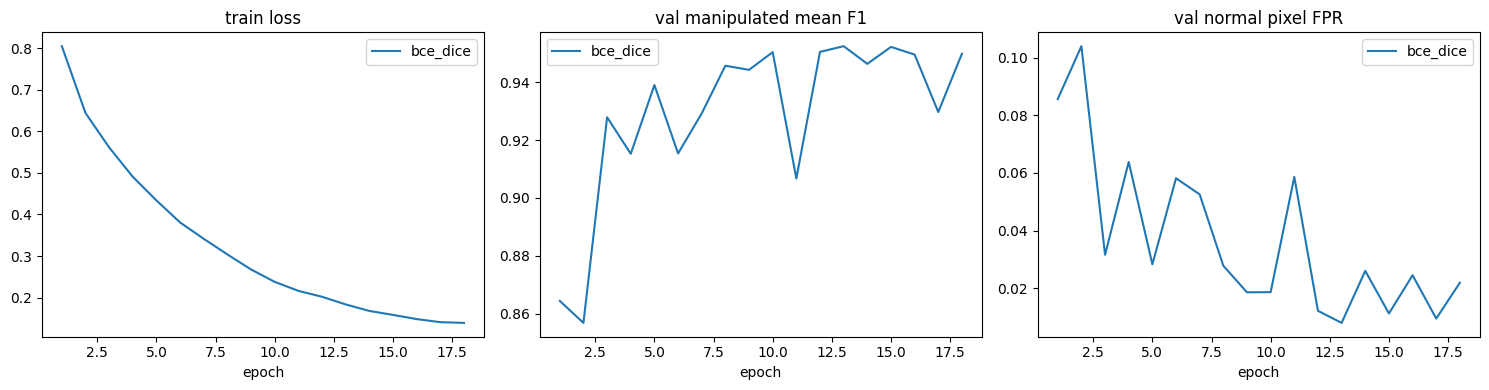

,condition,epochs_run,best_epoch,val_f1,val_iou,val_normal_fpr,peak_gpu_gib,minutes
0,bce_dice,18,13,0.952483,0.912749,0.008006,3.247983,15.960156


손실 조건: bce_dice (002에서 val 기준으로 선택)


In [7]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for condition, group in history.groupby("condition", sort=False):
    axes[0].plot(group.epoch, group.train_loss, label=condition)
    axes[1].plot(group.epoch, group.val_f1, label=condition)
    axes[2].plot(group.epoch, group.val_normal_fpr, label=condition)
for axis, title in zip(axes, ["train loss", "val manipulated mean F1", "val normal pixel FPR"]):
    axis.set_title(title)
    axis.set_xlabel("epoch")
    axis.legend()
plt.tight_layout()
plt.show()

selection = []
for condition in conditions:
    done = json.loads((run_root / condition / "done.json").read_text())
    best = history[(history.condition == condition) & (history.epoch == done["best_epoch"])].iloc[0]
    selection.append(dict(condition=condition, epochs_run=done["epochs_run"], best_epoch=done["best_epoch"],
                          val_f1=best.val_f1, val_iou=best.val_iou, val_normal_fpr=best.val_normal_fpr,
                          peak_gpu_gib=done["peak_gpu_gib"],
                          minutes=(history[history.condition == condition][["train_seconds", "val_seconds"]].sum().sum()) / 60))
selection = pd.DataFrame(selection)
with pd.option_context("display.float_format", "{:.6f}".format):
    display(selection)
print("손실 조건:", conditions[0], "(002에서 val 기준으로 선택)")

## 6. 테스트 평가

최고 val 체크포인트로 test를 평가함. test 결과로 설정을 바꾸지 않음. 결과는 004와 같은 묶음(데이터셋·분할·변형·입력 변환·종류)으로 이미지별 점수를 평균함. 이미지별 결과는 Drive의 조건 폴더에 `test_rows.csv`로 저장함.

In [8]:
vis_rng = np.random.default_rng(seed)
vis_names = []
for dataset, kind in [("AutoSplice", "manipulated"), ("AutoSplice", "manipulated"), ("AutoSplice", "normal"),
                      ("CocoGlide", "manipulated"), ("CocoGlide", "normal")]:
    candidates = [r for r in test_records if r["dataset"] == dataset and r["kind"] == kind
                  and r.get("variant") in ("JPEG100", "original", "PNG") and str(r["input_path"]) not in vis_names]
    vis_names.append(str(candidates[int(vis_rng.integers(len(candidates)))]["input_path"]))

test_summaries, kept_by_condition = [], {}
group_columns = ["dataset", "split", "variant", "input_conversion", "kind"]
for condition in conditions:
    checkpoint = torch.load(run_root / condition / "best.pt", map_location=device)
    if checkpoint["config_hash"] != config_hash:
        raise ValueError(f"{condition}: 체크포인트 설정 해시가 현재 설정과 같아야 함.")
    model = ResNet50UNet(3).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    start = time.perf_counter()
    rows, kept_by_condition[condition] = evaluate(model, test_records, keep=set(vis_names))
    seconds = time.perf_counter() - start
    rows.to_csv(run_root / condition / "test_rows.csv", index=False)
    summary = rows.groupby(group_columns).agg(images=("image", "size"), pixel_f1=("f1", "mean"), iou=("iou", "mean"),
                                              normal_pixel_fpr=("fpr", "mean")).reset_index()
    summary.insert(0, "condition", condition)
    test_summaries.append(summary)
    print(f"[{condition}] best epoch {checkpoint['epoch']}, test {len(rows)}장 평가 {seconds:.0f}s")
    del model

test_summary = pd.concat(test_summaries, ignore_index=True)
with pd.option_context("display.float_format", "{:.6f}".format, "display.max_rows", None, "display.width", 200):
    display(test_summary)
    pivot = test_summary.assign(score=test_summary.pixel_f1.fillna(test_summary.normal_pixel_fpr),
                                metric=np.where(test_summary.kind == "manipulated", "F1", "normal FPR"))
    display(pivot.pivot_table(index=["dataset", "variant", "metric"], columns="condition", values="score", sort=False)[conditions])

[bce_dice] best epoch 13, test 2257장 평가 41s


,condition,dataset,split,variant,input_conversion,kind,images,pixel_f1,iou,normal_pixel_fpr
0,bce_dice,AutoSplice,test,JPEG100,none,manipulated,335,0.957054,0.921905,NaN
1,bce_dice,AutoSplice,test,JPEG75,none,manipulated,335,0.008440,0.004907,NaN
2,bce_dice,AutoSplice,test,JPEG90,none,manipulated,335,0.000959,0.000514,NaN
3,bce_dice,AutoSplice,test,original,none,normal,228,NaN,NaN,0.012541
4,bce_dice,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,manipulated,512,0.359235,0.254559,NaN
5,bce_dice,CocoGlide,external_test,PNG,PNG_to_JPEG100_444,normal,512,NaN,NaN,0.941426


condition                       bce_dice
dataset    variant  metric              
AutoSplice JPEG100  F1          0.957054
           JPEG75   F1          0.008440
           JPEG90   F1          0.000959
           original normal FPR  0.012541
CocoGlide  PNG      F1          0.359235
                    normal FPR  0.941426

## 7. 예측 시각화

test에서 002와 같은 고정 시드로 고른 AutoSplice JPEG100 조작 2장·정상 1장, CocoGlide 조작 1장·정상 1장의 ELA 입력과 예측 확률을 보여 줌. 정성 확인용이며 표본 선택은 점수를 보기 전에 정함.

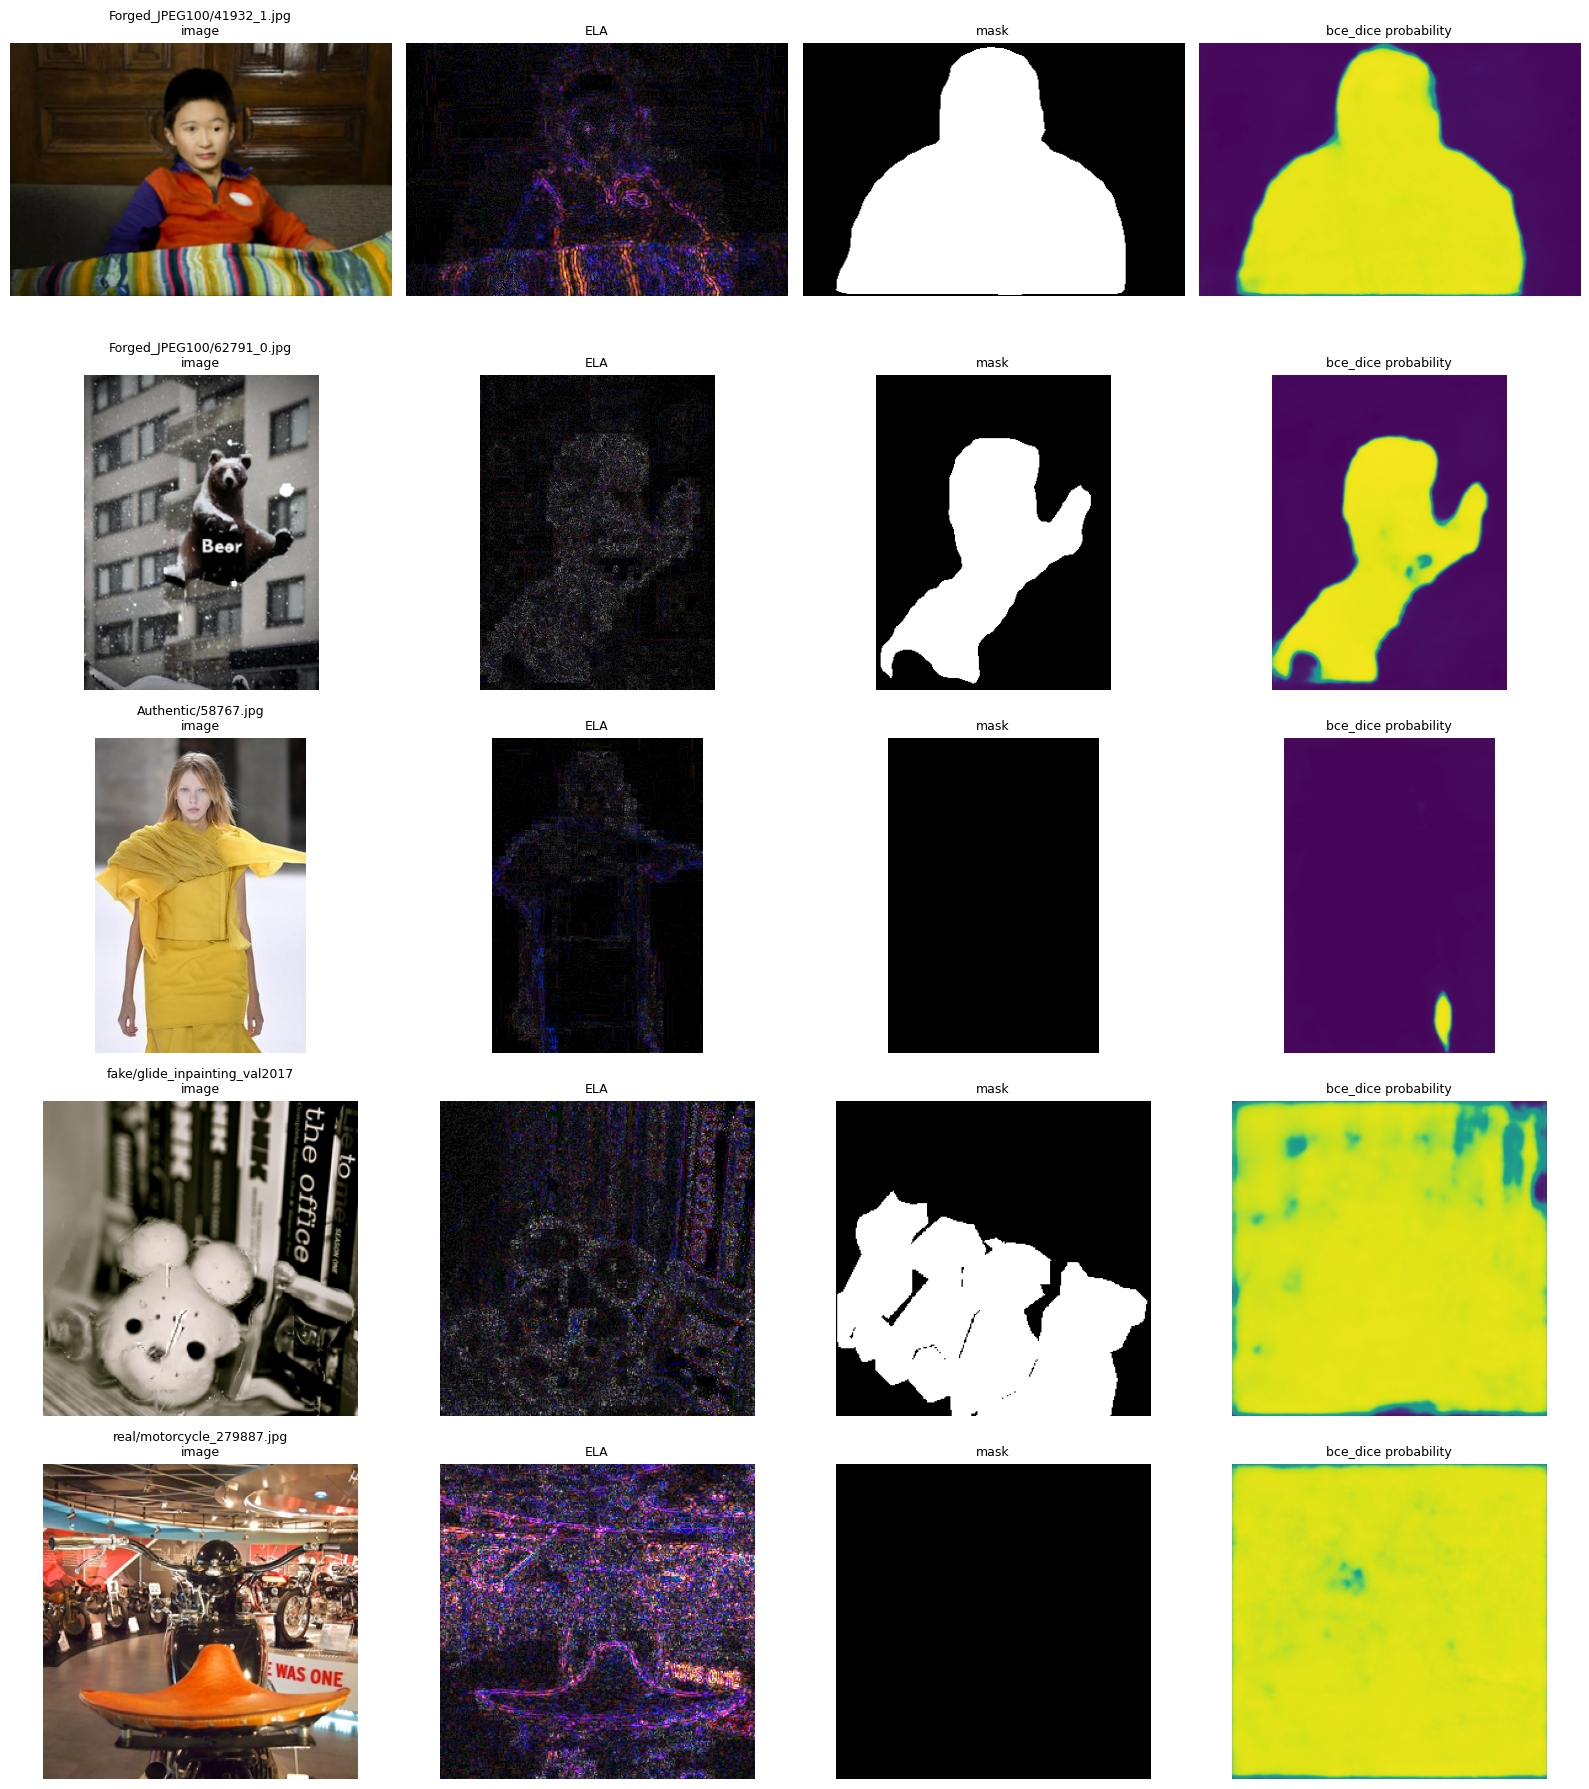

In [9]:
figure, axes = plt.subplots(len(vis_names), 3 + len(conditions), figsize=(4 * (3 + len(conditions)), 3.6 * len(vis_names)))
for row, name in enumerate(vis_names):
    rgb, ela, mask, _ = kept_by_condition[conditions[0]][name]
    panels = [(rgb, "image", None), (ela, "ELA", None), (mask, "mask", "gray")]
    for condition in conditions:
        panels.append((kept_by_condition[condition][name][3], f"{condition} probability", "viridis"))
    for column, (image, title, cmap) in enumerate(panels):
        axes[row, column].imshow(image, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
        axes[row, column].set_title(f"{Path(name).parent.name}/{Path(name).name[:24]}\n{title}" if column == 0 else title, fontsize=9)
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()

## 8. 확인 결과와 검토 메모

아래 셀은 실행 범위를 요약함. 해석과 성공·실패 사례 분석은 보고서에 작성함.

사람 검토 메모(실행 후 작성):

- 3절 ELA 크롭 그림의 마스크 대응:
- 5절 학습 곡선(과적합·조기 종료 시점):
- 7절 ELA·예측 그림의 성공·실패 사례:
- 특이사항(실행 시간, 끊김·재실행 여부 등):

In [10]:
print("설정 해시:", config_hash)
print("실행 기록 폴더:", run_root)
for condition in conditions:
    done = json.loads((run_root / condition / "done.json").read_text())
    print(f"{condition}: epoch {done['epochs_run']}회 학습, best epoch {done['best_epoch']}, val F1 {done['best_val_f1']:.6f}")
print("손실:", conditions[0])
print("테스트 평가 행 수:", len(test_summary))
print("실험 완료. test 결과로 설정을 바꾸지 않음")

설정 해시: 80b40e261b31
실행 기록 폴더: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_003_ela_unet_baseline
bce_dice: epoch 18회 학습, best epoch 13, val F1 0.952483
손실: bce_dice
테스트 평가 행 수: 6
실험 완료. test 결과로 설정을 바꾸지 않음
